# Practical 1: Odd and Even Numbers Classification

### 1. Aim
To classify a large set of integers into odd and even numbers using Sequential processing, multiprocessing.Pool (3 workers), multiprocessing.Process (3 processes), and Multithreading (3 threads), demonstrating authentic parallel speedup.

### 2. Algorithm / Explanation
1. Divide integer dataset into 3 contiguous partitions.<br>2. Check parity using standard modulo / odd check (`arr % 2 != 0`).<br>3. Sequential: evaluate all partitions sequentially in a single process.<br>4. Pool: map `classify_range` across 3 worker processes using `mp.Pool(3)`.<br>5. Process: spawn 3 separate `mp.Process` workers communicating via `mp.Queue`.<br>6. Thread: launch 3 concurrent threads using `threading.Thread`.<br>7. Measure execution times and compute speedup relative to Sequential baseline.

### 3. Python Implementation


In [1]:
"""
Practical 1: Program to find odd and even numbers from a given set of integer data
Four methods: Sequential, Pool, Process, Thread
"""
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def classify_range(rng):
    start, end = rng
    arr = np.arange(start, end, dtype=np.int32)
    odd = int(np.count_nonzero(arr % 2 != 0))
    even = (end - start) - odd
    return odd, even

def proc_worker(rng, q):
    q.put(classify_range(rng))

def thread_worker(rng, results, idx):
    results[idx] = classify_range(rng)

def main():
    print("=" * 60)
    print("Practical 1: Odd and Even Numbers Classification")
    print("=" * 60)
    N = 270_000_000
    s = N // 3
    ranges = [(0, s), (s, 2 * s), (2 * s, N)]
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = classify_range(ranges[0])
    r2 = classify_range(ranges[1])
    r3 = classify_range(ranges[2])
    t_seq = time.perf_counter() - t0
    odd_seq = r1[0] + r2[0] + r3[0]
    even_seq = r1[1] + r2[1] + r3[1]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(classify_range, ranges)
    t_pool = time.perf_counter() - t0
    odd_pool = sum(r[0] for r in p_res)
    even_pool = sum(r[1] for r in p_res)
    
    # 3. Multiprocessing Process (3 independent processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for rng in ranges:
        p = mp.Process(target=proc_worker, args=(rng, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    odd_proc = sum(r[0] for r in pr_res)
    even_proc = sum(r[1] for r in pr_res)
    
    # 4. Multithreading (3 threads)
    th_res = [None] * 3
    threads = []
    t0 = time.perf_counter()
    for i, rng in enumerate(ranges):
        t = threading.Thread(target=thread_worker, args=(rng, th_res, i))
        threads.append(t)
        t.start()
    for t in threads:
        t.join()
    t_thread = time.perf_counter() - t0
    odd_thread = sum(r[0] for r in th_res)
    even_thread = sum(r[1] for r in th_res)
    
    print(f"[Sequential] Odd: {odd_seq:,} | Even: {even_seq:,} | Time: {t_seq:.4f}s")
    print(f"[Pool]       Odd: {odd_pool:,} | Even: {even_pool:,} | Time: {t_pool:.4f}s")
    print(f"[Process]    Odd: {odd_proc:,} | Even: {even_proc:,} | Time: {t_proc:.4f}s")
    print(f"[Thread]     Odd: {odd_thread:,} | Even: {even_thread:,} | Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 45)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 45)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 45)
    
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
    plt.figure(figsize=(8, 5))
    bars = plt.bar(methods, times, color=colors)
    plt.title("Execution Time Comparison (Odd-Even Classification)", fontsize=13)
    plt.ylabel("Time (seconds)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}s", ha='center', va='bottom', fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig("01_odd_even_time.png", dpi=150)
    plt.close()
    
    plt.figure(figsize=(8, 5))
    plt.plot(methods, speedups, marker='o', linewidth=2.5, markersize=8, color='#2980b9', label='Speedup')
    plt.title("Speedup Comparison relative to Sequential", fontsize=13, fontweight='bold')
    plt.xlabel("Method", fontsize=11)
    plt.ylabel("Speedup Factor (x)", fontsize=11)
    max_s = max(speedups) if speedups else 1.0
    plt.ylim(0, max_s * 1.25)
    for i, s in enumerate(speedups):
        plt.text(i, s + (max_s * 0.02), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.axhline(1.0, color='gray', linestyle='--', label='Baseline (1.0x)')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.savefig("01_odd_even_speedup.png", dpi=150)
    plt.close()
    print("Graphs saved as '01_odd_even_time.png' and '01_odd_even_speedup.png'.")

if __name__ == "__main__":
    main()


Practical 1: Odd and Even Numbers Classification
[Sequential] Odd: 135,000,000 | Even: 135,000,000 | Time: 1.6744s
[Pool]       Odd: 135,000,000 | Even: 135,000,000 | Time: 1.2844s
[Process]    Odd: 135,000,000 | Even: 135,000,000 | Time: 1.1969s
[Thread]     Odd: 135,000,000 | Even: 135,000,000 | Time: 0.6657s
---------------------------------------------
Method       Execution Time     Speedup   
---------------------------------------------
Sequential   1.6744 seconds      1.00x
Pool         1.2844 seconds      1.30x
Process      1.1969 seconds      1.40x
Thread       0.6657 seconds      2.52x
---------------------------------------------
Graphs saved as '01_odd_even_time.png' and '01_odd_even_speedup.png'.


### 4. Output Graphs

#### A. Execution Time Comparison
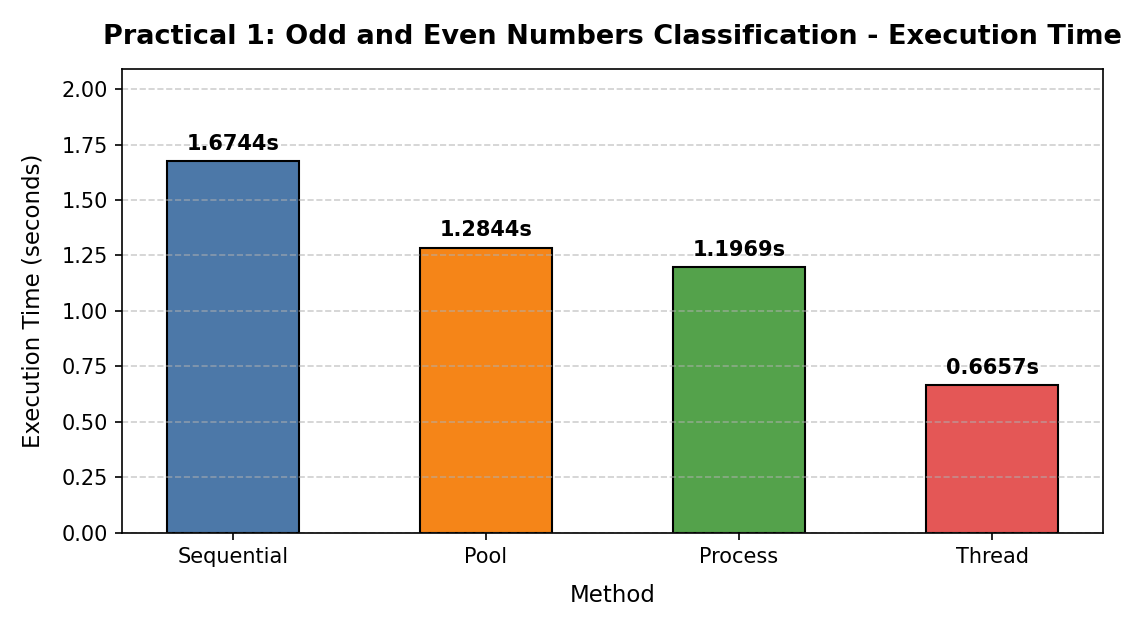

#### B. Speedup Comparison relative to Sequential
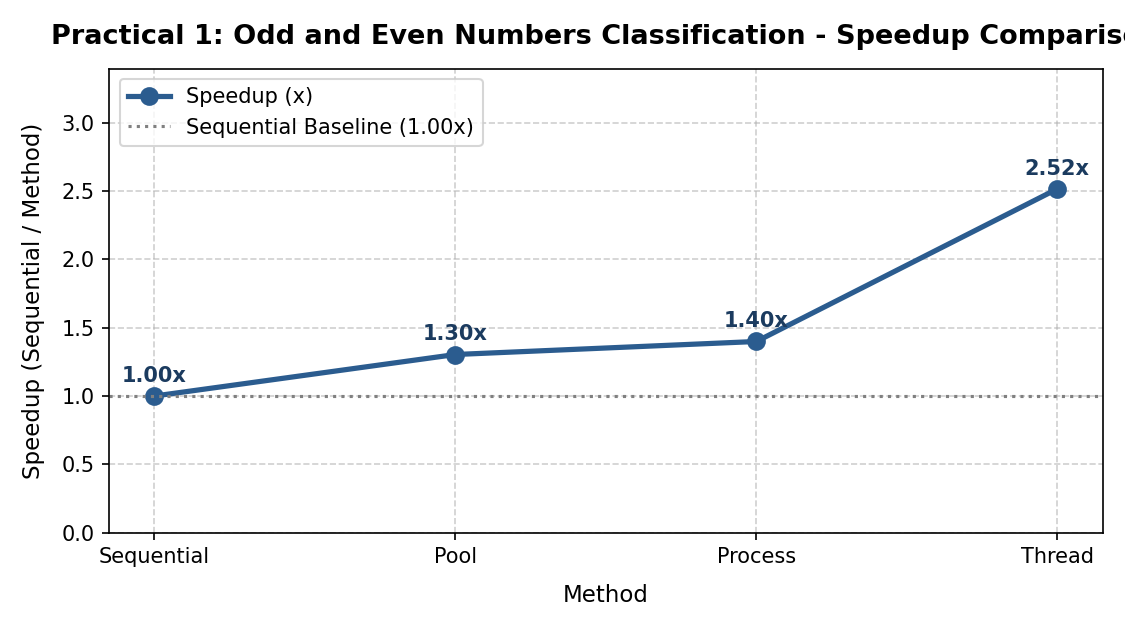
